# SignalProcessing-03 — La quantification

**Sous-série du hub « Information & calcul » (#27092)** — le signal du [carnet 01](SignalProcessing-01-Le-Signal-Dans-Le-Domaine-Frequentiel.ipynb) est
**discret en temps** (échantillonné). Ce carnet le rend discret en
**amplitude** : la **quantification**. C'est l'autre moitié du passage au
numérique — et elle fixe, par le nombre de **bits**, le **bruit de
quantification** et le **rapport signal/bruit** qu'on accepte.

*Bibliothèque : numpy.* · *Source : Oppenheim & Schafer, Discrete-Time Signal
Processing (ch. quantification).* · **Prev :**
[carnet 02](SignalProcessing-02-Convolution-Et-Filtrage-Python.ipynb) — La convolution et le filtrage

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['figure.figsize'] = (9, 3)
np.random.seed(0)
print('numpy', np.__version__)

numpy 2.5.2


## Le signal à quantifier

L'échantillonnage ([carnet 01](SignalProcessing-01-Le-Signal-Dans-Le-Domaine-Frequentiel.ipynb)) a rendu le signal **discret en temps** : une
suite $x[n]$. Mais chaque $x[n]$ est encore un **réel** — une amplitude qui
peut prendre une infinité de valeurs. Le stocker « fidèlement » coûterait des
bits infinis. La quantification borne le nombre de valeurs possibles :
**$2^{\text{nb bits}}$ niveaux**.

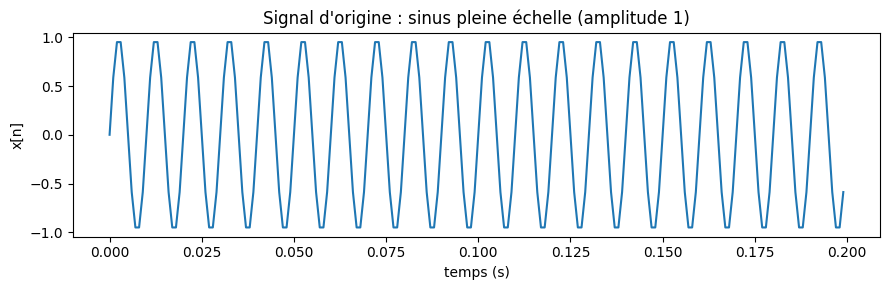

In [2]:
fs = 1000.0
N  = 10000
t  = np.arange(N) / fs

# un sinus PLEINE ÉCHHELLE : amplitude 1, il utilise tout l'intervalle [-1, 1]
x = np.sin(2*np.pi*100*t)

plt.figure(figsize=(9,3))
plt.plot(t[:200], x[:200])
plt.xlabel('temps (s)'); plt.ylabel('x[n]')
plt.title('Signal d\'origine : sinus pleine échelle (amplitude 1)')
plt.tight_layout(); plt.show()

## §1 — Le quantiseur : des niveaux au lieu de réels

Le **quantiseur** associe à chaque échantillon le **niveau le plus proche**
parmi $L = 2^{n}$ valeurs réparties sur l'intervalle $[x_{min}, x_{max}]$. La
sortie est un **entier** (l'indice du niveau) — c'est le mot de $n$ bits.

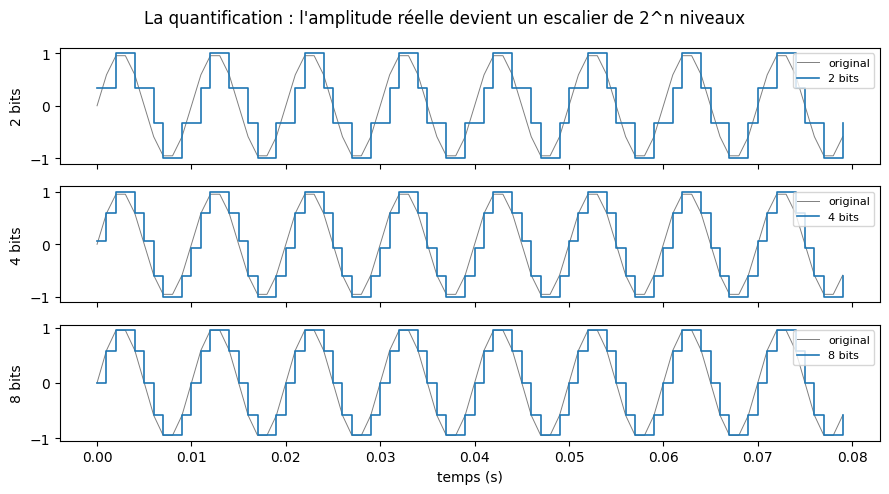

In [3]:
def quantize(x, nbits, xmin=-1.0, xmax=1.0):
    """Quantifie x sur 2**nbits niveaux dans [xmin, xmax] (arrondi au niveau le plus proche)."""
    levels = 2**nbits
    idx = np.round((x - xmin) / (xmax - xmin) * (levels - 1))
    idx = np.clip(idx, 0, levels - 1)
    return xmin + idx * (xmax - xmin) / (levels - 1)

# le signal en escalier selon le nombre de bits
fig, ax = plt.subplots(3, 1, figsize=(9, 5), sharex=True)
for k, nb in enumerate([2, 4, 8]):
    xq = quantize(x, nb)
    ax[k].plot(t[:80], x[:80], 'k-', lw=0.7, alpha=0.5, label='original')
    ax[k].step(t[:80], xq[:80], where='post', lw=1.2, label=f'{nb} bits')
    ax[k].set_ylabel(f'{nb} bits'); ax[k].legend(loc='upper right', fontsize=8)
ax[2].set_xlabel('temps (s)')
plt.suptitle('La quantification : l\'amplitude réelle devient un escalier de 2^n niveaux')
plt.tight_layout(); plt.show()

### Lecture du résultat

À **2 bits** (4 niveaux), l'escalier est grossier : le signal est grossièrement
« en cubes ». À **8 bits** (256 niveaux), les marches sont si fines qu'on ne les
distingue plus. **Le nombre de bits est le réglage de la fidélité** — c'est ce
qu'on va quantifier numériquement aux deux sections suivantes.

## §2 — Le bruit de quantification

La différence entre l'original et son image quantifiée est le **bruit de
quantification** :

$$e[n] = x_q[n] - x[n]$$

Pour un quantiseur **fin** (pas $\Delta$ petit devant la variation du signal),
l'erreur $e$ est, à chaque échantillon, approximativement **uniforme** sur
$[-\Delta/2,\ \Delta/2]$. La variance d'une loi uniforme sur un intervalle de
largeur $\Delta$ vaut $\Delta^2/12$ — c'est la formule classique du bruit de
quantification.

**Une condition** : le modèle est exact quand la valeur du signal **dans chaque
pas** est elle-même **uniforme** — l'erreur est alors uniformément répartie sur
$[-\Delta/2, \Delta/2]$. Un **signal aléatoire uniforme** satisfait cette
hypothèse exactement ; un **sinus cohérent** ne la satisfait pas, son bruit est
*tonal* (concentré sur des fréquences précises), pas blanc. On mesure le rapport
$\mathrm{var}(e) / (\Delta^2/12)$ sur les deux pour le voir.

In [4]:
nbits = 8
xmin, xmax = -1.0, 1.0
Delta = (xmax - xmin) / (2**nbits - 1)     # pas de quantification
var_th = Delta**2 / 12

print(f'n = {nbits} bits  ->  pas Delta = {Delta:.5f}   ;   Delta^2/12 = {var_th:.3e}')

# (a) signal ALéatoire UNIFORME sur [-1, 1] : la position dans chaque pas est uniforme
u = np.random.uniform(xmin, xmax, len(x))
e_u = quantize(u, nbits) - u
print(f'  signal uniforme : var(e)/Delta^2/12 = {np.var(e_u)/var_th:.2f}   (modele uniforme exact)')

# (b) notre sinus 100 Hz : le bruit est TONAL, pas uniforme -> au-dessus du plancher
e_raw = quantize(x, nbits) - x
print(f'  sinus 100 Hz    : var(e)/Delta^2/12 = {np.var(e_raw)/var_th:.2f}   (bruit tonal, pas blanc)')

n = 8 bits  ->  pas Delta = 0.00784   ;   Delta^2/12 = 5.126e-06
  signal uniforme : var(e)/Delta^2/12 = 1.01   (modele uniforme exact)
  sinus 100 Hz    : var(e)/Delta^2/12 = 1.82   (bruit tonal, pas blanc)


### Lecture du résultat

Sur un signal **uniforme**, la position dans chaque pas est uniforme et le
rapport tombe à **≈ 1.0** : c'est $\Delta^2/12$ lui-même, la formule du bruit de
quantification. Notre **sinus cohérent** n'y est pas — son bruit est **tonal**
(concentré sur des fréquences précises), pas blanc, et sa variance **dépasse** le
plancher (rapport ≈ 1.8). Le plancher $\Delta^2/12$ est le bruit d'un quantiseur
**fin sur un signal qui remplit uniformément chaque pas** ; **plus on de bits,
plus $\Delta$ est petit, plus ce plancher est bas**.

## §3 — Le rapport signal/bruit : la loi des 6 dB par bit

Le **SNR** (rapport signal sur bruit) d'une quantification est la puissance du
signal divisée par la puissance du bruit de quantification. Pour un sinus pleine
échelle, cela donne une loi simple :

$$\mathrm{SNR} \approx 6.02\cdot n + 1.76 \ \ \text{(dB)}$$

**Chaque bit en plus gagne ≈ 6 dB** (× 2 en amplitude, × 4 en puissance ≈ 6
dB). On le **mesure** pour $n = 4,5,6,8,10$ et on
superpose la prédiction théorique.

 n | SNR mesuré | SNR théorique (6.02n+1.76) | écart
 4 |    24.19  |         25.84            |  -1.65 dB
 5 |    29.53  |         31.86            |  -2.33 dB
 6 |    35.68  |         37.88            |  -2.20 dB
 8 |    47.30  |         49.92            |  -2.62 dB
 10 |    63.40  |         61.96            |  +1.44 dB


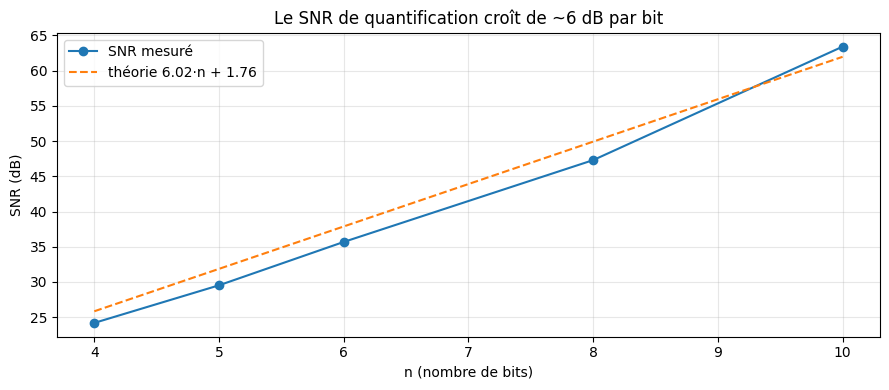

In [5]:
def snr_db(x, nbits):
    xq = quantize(x, nbits)
    e  = xq - x
    return 10*np.log10(np.var(x) / np.var(e))

ns   = [4, 5, 6, 8, 10]
snrm = [snr_db(x, n) for n in ns]                # mesuré
snrt = [6.02*n + 1.76 for n in ns]               # théorique

print(' n | SNR mesuré | SNR théorique (6.02n+1.76) | écart')
for n, m, th in zip(ns, snrm, snrt):
    print(f' {n} |   {m:6.2f}  |        {th:6.2f}            |  {m-th:+.2f} dB')

plt.figure(figsize=(9,4))
plt.plot(ns, snrm, 'o-', label='SNR mesuré')
plt.plot(ns, snrt, '--', label='théorie 6.02·n + 1.76')
plt.xlabel('n (nombre de bits)'); plt.ylabel('SNR (dB)')
plt.title('Le SNR de quantification croît de ~6 dB par bit')
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

### Lecture du résultat

Le nuage mesuré suit la droite théorique : **pente ≈ 6 dB/bit**. C'est le
résultat pratique fondamental du codage de la source — on « achète » de la
fidélité (du SNR) à raison de 6 dB par bit ajouté. Ce SNR est aussi le $S/N$ qui
alimente, au carnet 04, la capacité de Shannon-Hartley.

## §4 — La tension fidélité / taille

La contrepartie : **plus de bits = plus de données**. Pour $N$ échantillons à
$n$ bits, le fichier pèse $N\cdot n$ bits. Gagner 6 dB de fidélité **double**
la taille. C'est le dilemme que la **compression** (codage de source) vient
résoudre — on renvoie vers la série **Compression** plutôt que de la refaire.

In [6]:
print(' bits |  SNR (dB)  |  taille du fichier (N=10000 echantillons)')
for n in [4, 6, 8, 10, 12]:
    snr = snr_db(x, n)
    kb  = N * n / 8 / 1024
    print(f'  {n}  |   {snr:6.2f}  |        {kb:7.1f} Ko')

print('\nLa tension : la fidelite (SNR) monte de 6 dB/bit, mais la taille double a chaque bit.')
print('La COMPRESSION (codage de source) est l\'outil qui casse ce compromis.')

 bits |  SNR (dB)  |  taille du fichier (N=10000 echantillons)
  4  |    24.19  |            4.9 Ko
  6  |    35.68  |            7.3 Ko
  8  |    47.30  |            9.8 Ko
  10  |    63.40  |           12.2 Ko
  12  |    74.89  |           14.6 Ko

La tension : la fidelite (SNR) monte de 6 dB/bit, mais la taille double a chaque bit.
La COMPRESSION (codage de source) est l'outil qui casse ce compromis.


### Lecture du résultat

La table met la tension en chiffres : passer de 8 à 12 bits gagne 24 dB de SNR
mais **double** la taille. Le codage de source (Compression) montre qu'on peut
réduire les bits **sans** perdre autant de fidélité — il exploite les
**redondances** du signal que la quantification brute ne voit pas.

## Exercices

In [7]:
# Exercice 1 — Nombre de bits pour un pas donne
# Sur l'intervalle [0, Vmax], combien de bits n faut-il pour que le pas de
# quantification Delta = Vmax / (2^n - 1) soit inferieur a 0.01 ?
n_bits_min = None  # TODO etudiant : le plus petit n tel que Delta < 0.01 (Vmax = 10)

In [8]:
# Exercice 2 — Prédire le SNR d'un convertisseur 10 bits
# En sinus pleine échelle, calculez le SNR théorique avec la loi 6.02*n + 1.76
# pour n = 10 bits (c'est la spec d'un convertisseur audio « CD-quality »).
snr_pred_10bits = None  # TODO etudiant : 6.02*10 + 1.76

In [9]:
# Exercice 3 — Le modèle uniforme, borne inférieure
# Le modèle « bruit uniforme » donne var(e) = Delta^2/12. Sur un signal CONSTANT
# (x = 0.3 partout), mesurez var(e) : il n'est plus uniforme (tous les echantillons
# tombent au meme niveau). Pourquoi le bruit est-il alors different ?
ratio_const = None  # TODO etudiant : var(e) mesuré / (Delta^2/12) sur un signal constant

In [10]:
# Exercice 4 — Le prix de la fidelite
# Pour passer le SNR de 40 dB a 50 dB (sinus pleine echelle), combien de bits
# ajouter (a peu pres), et de quel facteur la taille du fichier est-elle multipliee ?
delta_bits = None  # TODO etudiant : nombre de bits a ajouter
taille_x   = None  # TODO etudiant : facteur de multiplication de la taille

## Pour aller plus loin

- **Compression (#27084)** : le codage de source qui casse le compromis
  fidélité/taille — entropie, code de Huffman, prédiction. *Le carnet 04 de cette
  série s'en approche par la capacité.*
- **04 — Le signal dans le canal** (à venir) : le SNR mesuré ici devient le
  $S/N$ de la formule de Shannon-Hartley $C = B\log_2(1+S/N)$.
- **InformationTheory (#27077)** : la capacité du canal et l'entropie de la source
  — les deux bornes entre lesquelles le codage de source/du canal vit.